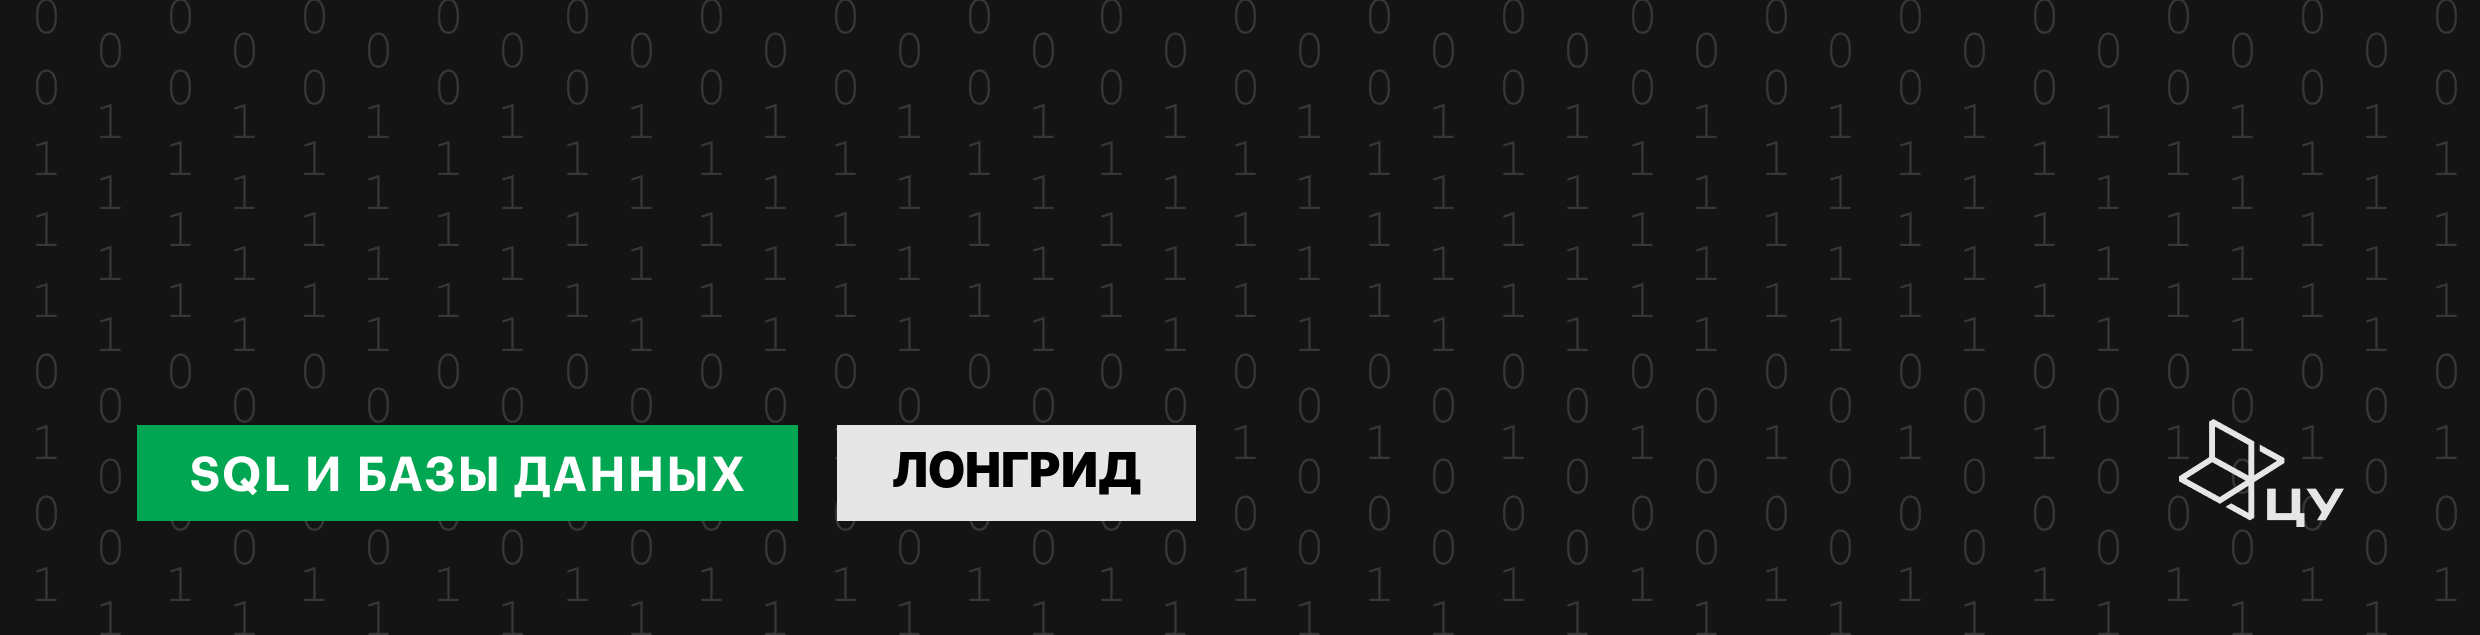

# Лонгрид по теме Операции над множествами. Подзапросы в условии поиска

В лонгриде есть задачи по ходу текста и в конце на понимание.

В этом материале сначала разбираются операции над множествами в SQL: UNION, UNION ALL, INTERSECT, EXCEPT и ALL-варианты. Затем идут подзапросы для фильтрации результатов: скалярные подзапросы, IN, ANY, ALL, EXISTS, Semi Join и Anti Join. Практические задания идут по ходу текста на маленьких учебных данных и на Bike Sales.



Логин и пароль для подключения к базам данных PostgreSQL можно получить в сервисе самообслуживания (https://self-service.culab.ru).
 При получении нового пароля старый пароль будет аннулирован.

У каждого студента есть своя схема в наших базах данных. Называется так же, как логин, используемый при подключении.

Схема с общими таблицами называется databases_and_sql. При выполнении запросов в данном ноутбуке эта схема используется по умолчанию.

Описание таблиц и схему БД можно посмотреть тут:

https://centraluniversity.yonote.ru/share/0188ee4d-d0bb-4654-9d49-87dab28e9550/doc/tablicy-ispolzuemye-v-kurse-sql-i-bazy-dannyh-kXDYWB70FN

In [ ]:
import os,requests,time;url = "http://sql-exercise.sql-exercise-prod.svc.cluster.local/"
if os.path.exists("py_workshop.py"):
    os.remove("py_workshop.py")
if not os.path.exists("py_workshop.py"):
    response = requests.get(f"{url}get_py_workshop");
    if response.status_code == 200: 
        with open("py_workshop.py", "wb") as f: f.write(response.content);time.sleep(1)
# Проверь, что config.yaml (надо заполнить по инструкции) и py_workshop.py (скачается автоматически) находятся в папке с этим ноутбуком
from py_workshop import *;runner.set_url(url);runner.logon();schema_name = runner.user_schema
runner.course = 'sql'
runner.material( 'sqldb_an26_sql_sets_subqueries_longread', course_launch='dbsql_an_onl_26_fall')

# Операции над множествами и подзапросы в SQL

## Введение

В аналитике часто нужно:

- объединить результаты из нескольких таблиц с одинаковой структурой;
- найти общие элементы двух наборов;
- найти различия между наборами;
- подготовить «сводку» из разных источников без джойнов (когда связи между таблицами нет или не нужна).

Для этого в SQL есть операции над множествами: UNION, UNION ALL, INTERSECT, INTERSECT ALL, EXCEPT и EXCEPT ALL.

В этом лонгриде разберём синтаксис, примеры, продвинутые случаи с сортировкой/фильтрацией/группировкой, особенности производительности и типовые ошибки.

## Что такое операции над множествами

Операции над множествами объединяют результаты двух и более запросов (каждый запрос — это «множество»).

UNION — объединение двух наборов данных с неявной дедупликацией, то есть результат операции даст уникальные строки.

UNION ALL — объединение с сохранением дублей.

INTERSECT — пересечение, операция даёт уникальные строки, присутствующие в обеих выборках.

EXCEPT — разность, операция даёт уникальные строки из первой выборки, которых нет во второй.

Варианты INTERSECT ALL и EXCEPT ALL учитывают кратность строк, но используются крайне редко.

### Основные требования к множествам (таблицам или запросам)

- В каждом запросе или таблице должен быть одинаковый набор столбцов (по количеству).
- Соответствующие столбцы должны быть совместимых типов (чтобы СУБД смогла привести их к общему типу).
- Алиасы столбцов берутся из первого запроса или таблицы.

## Базовый синтаксис

```sql
SELECT ...         -- множество 1
FROM ...
[WHERE ...]
[GROUP BY ...]
[HAVING ...]
[ORDER BY ...]     -- действует только в пределах подзапроса, если есть LIMIT (см. ниже)

UNION | UNION ALL | INTERSECT | EXCEPT

SELECT ...         -- множество 2
FROM ...
...
```

Чтобы сортировать/фильтровать общий результат, оборачиваем всю операцию в подзапрос и пишем ORDER BY / WHERE / GROUP BY снаружи (подробно — ниже).

### Задача 1. UNION ALL: собрать заказы за два периода

Мини-задача показывает базовый смысл операции над множествами: мы берём два одинаковых по структуре набора строк и складываем их в один общий результат. Здесь `UNION ALL` подходит лучше, потому что мы не хотим случайно удалить совпадающие заказы.

Вставь код в ячейку.

```sql
with orders_jan(order_id, customer_id, amount) as (
    values
        (1, 101, 1200),
        (2, 102, 800),
        (3, 101, 500)
),
orders_feb(order_id, customer_id, amount) as (
    values
        (4, 103, 1500),
        (5, 102, 700),
        (6, 104, 300)
)
select order_id, customer_id, amount, 'jan' as period
from orders_jan
union all
select order_id, customer_id, amount, 'feb' as period
from orders_feb
order by order_id
```



In [ ]:
%%sql_query cell_1_1
-- Задача 1. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_1_2
--Проверка запроса для задачи 1. Отправь SQL-запрос на проверку


### Задача 2. Bike Sales: общий справочник клиентов и товаров

Пример на нормальной учебной БД Bike Sales. Мы объединяем клиентов и товары в один «поисковый» список. Обрати внимание на `::text`: у клиентов и товаров разные числовые идентификаторы, но в общем результате один столбец должен иметь один тип.

Вставь код в ячейку.

```sql
select customer_id::text as entity_id,
       'customer' as entity_type,
       trim(coalesce(first_name, '') || ' ' || coalesce(last_name, '')) as entity_name
from bs_customer
union all
select product_id::text as entity_id,
       'product' as entity_type,
       name as entity_name
from bs_product
order by entity_type, entity_id
limit 20
```

*Примечание: сам факт того, что один идентификатор относится к товару, а другой — к клиенту, не требует обязательного приведения к текстовому представлению идентификатора. В данном примере это сделано для достоверности, что идентификаторы товаров и клиентов имеют один и тот же тип.*



In [ ]:
%%sql_query cell_2_1
-- Задача 2. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_2_2
--Проверка запроса для задачи 2. Отправь SQL-запрос на проверку


## Часто операции над множествами нужны с удалением дублей. Далее несколько простых примеров

### UNION 

UNION — все уникальные строки из двух множеств.

**Исходные данные**

| w_country |    | w_city |    |
|----|----|----|----|
| name | pop | name | pop |
| France | 67M | Paris | 2M |
| Spain | 47M | Madrid | 3M |
| Italy | 60M | Rome | 2.8M |
| Andorra | 0.08M | Andorra | 0.02M |

**SQL**

```sql

SELECT name AS geo_name, 'country' AS geo_type

FROM w_country

UNION

SELECT name AS geo_name, 'city' AS geo_type

FROM w_city;
```

**Результат**

| geo_name | geo_type |
|----|----|
| France | country |
| Spain | country |
| Italy | country |
| Andorra | country |
| Paris | city |
| Madrid | city |
| Rome | city |
| Andorra | city |

### INTERSECT 

INTERSECT — только те строки, что есть в обоих множествах (уникальные).

Найти страны и города с одинаковым названием. 

**Исходные данные**

| w_city |    | w_country |    |
|----|----|----|----|
| name | pop | name | pop |
| Paris | 2M | France | 67M |
| Andorra | 0.02M | Andorra | 0.08M |
| Rome | 2.8M | Italy | 60M |

**SQL**

```sql

SELECT name FROM w_city

INTERSECT

SELECT name FROM w_country;
```

**Результат**

| name |
|----|
| Andorra |

### EXCEPT

EXCEPT — строки из 1‑й выборки, которых нет во 2‑й (уникальные)

Найти страны, у которых нет города с таким же названием. 

**Исходные данные**

| w_country |    | w_city |    |
|----|----|----|----|
| name | pop | name | pop |
| France | 67M | Paris | 2M |
| Spain | 47M | Madrid | 3M |
| Andorra | 0.08M | Andorra | 0.02M |

**SQL**

```sql

SELECT name FROM w_country

EXCEPT

SELECT name FROM w_city;
```

**Результат**

| name |
|----|
| France |
| Spain |

### Задача 3. UNION: уникальные клиенты из двух каналов

Повтори идею `UNION`: результат содержит уникальные строки из двух наборов. Дубль `103` внутри первого набора и совпадение `103` между наборами исчезнут.

Вставь код в ячейку.

```sql
with web_customers(customer_id) as (
    values (101), (102), (103), (103)
),
app_customers(customer_id) as (
    values (103), (104), (105)
)
select customer_id
from web_customers
union
select customer_id
from app_customers
order by customer_id
```



In [ ]:
%%sql_query cell_3_1
-- Задача 3. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_3_2
--Проверка запроса для задачи 3. Отправь SQL-запрос на проверку


### Задача 4. INTERSECT: клиенты, купившие в оба месяца

`INTERSECT` оставляет только строки, которые есть в обоих наборах. В этой задаче нужно найти клиентов, которые покупали и в январе, и в феврале.

Вставь код в ячейку.

```sql
with buyers_jan(customer_id) as (
    values (101), (102), (103), (104)
),
buyers_feb(customer_id) as (
    values (103), (104), (105)
)
select customer_id
from buyers_jan
intersect
select customer_id
from buyers_feb
order by customer_id
```



In [ ]:
%%sql_query cell_4_1
-- Задача 4. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_4_2
--Проверка запроса для задачи 4. Отправь SQL-запрос на проверку


### Задача 5. EXCEPT: клиенты без покупок

`EXCEPT` вычитает второй набор из первого. Здесь первый набор — все клиенты, второй — клиенты с покупками. В результате останутся клиенты без покупок.

Вставь код в ячейку.

```sql
with customers(customer_id) as (
    values (101), (102), (103), (104), (105)
),
buyers(customer_id) as (
    values (101), (103), (105)
)
select customer_id
from customers
except
select customer_id
from buyers
order by customer_id
```



In [ ]:
%%sql_query cell_5_1
-- Задача 5. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_5_2
--Проверка запроса для задачи 5. Отправь SQL-запрос на проверку


## Операции с сохранением дублей, нужны реже и в довольно специфичных случаях. Далее несколько примеров

Ниже три примера, где вариант `ALL` даёт **смысловой** эффект, где кратность вхождения дублей действительно важна.

### `UNION ALL`: конкатенация дневных логов кликов (без удаления дублей)

**Идея.** У нас есть логи кликов за два дня. Одинаковые строки возможны: повторная отправка события со стороны клиента/SDK, ретраи, дубликаты со стороны брокера. Нам важно сохранить **все** события (в т. ч. дубликаты), а дедупликацию делать уже в витрине, где она осмысленна (например, по event_id).

**Исходные данные**

| events_day1 |    |    |    | events_day2 |    |    |    |
|----|----|----|----|----|----|----|----|
| event_id | user_id | page | ts | event_id | user_id | page | ts |
| e101 | u1 | /plp | 10:01 | e201 | u2 | /plp | 11:02 |
| e102 | u1 | /pdp | 10:03 | e202 | u1 | /pdp | 11:05 |
| e103 | u2 | /plp | 10:07 | e202 | u1 | /pdp | 11:05 (полный дубль) |
| e104 | u3 | /home | 10:10 | e204 | u3 | /cart | 11:06 |

**SQL**

```sql

SELECT event_id, user_id, page, ts
FROM events_day1

UNION ALL

SELECT event_id, user_id, page, ts
FROM events_day2;
```

**Результат** 

| event_id | user_id | page | ts |
|----|----|----|----|
| e101 | u1 | /plp | 10:01 |
| e102 | u1 | /pdp | 10:03 |
| e103 | u2 | /plp | 10:07 |
| e104 | u3 | /home | 10:10 |
| e201 | u2 | /plp | 11:02 |
| e202 | u1 | /pdp | 11:05 |
| e202 | u1 | /pdp | 11:05 |
| e204 | u3 | /cart | 11:06 |


> **Зачем ALL?** Нам нельзя терять повторные события до стадий очистки, иначе собьём метрики, где нужны «сырые» клики (например, мониторинг ретраев/дубликатов SDK).


### `INTERSECT ALL`: «повторяющиеся покупки» по месяцам (учитываем кратность)

INTERSECT ALL учитывает кратность: строка вернётся столько раз, сколько она встречается минимально в обеих выборках.

**Идея.** Смотрим товары, которые покупал пользователь **и в январе, и в феврале**. Если товар взяли 3 раза в январе и 1 раз в феврале, в `INTERSECT ALL` он появится **1** раз как «минимальная повторяемость». Это удобно для оценки «стабильно повторяющихся» позиций.

**Исходные данные**

| order_items_jan |    |    |    | order_items_feb |    |    |    |
|----|----|----|----|----|----|----|----|
| user_id | product_id | qty | ts | user_id | product_id | qty | ts |
| u1 | A | 1 | 01 | u1 | A | 1 | 02 |
| u1 | A | 1 | 05 | u1 | A | 1 | 14 |
| u1 | B | 1 | 07 | u1 | B | 1 | 20 |
| u1 | A | 1 | 21 | u1 | C | 1 | 22 |


> Для простоты считаем поштучные покупки (одна строка = 1 ед.). Так кратность формируется **строками**.


**SQL**

```sql

SELECT user_id, product_id

FROM order_items_jan

INTERSECT ALL

SELECT user_id, product_id

FROM order_items_feb;
```

**Результат**

| user_id | product_id |
|----|----|
| u1 | A |
| u1 | A |
| u1 | B |


> **Почему ALL?** Без `ALL` пересечение вернуло бы просто {A, B}. С `ALL` мы видим, «насколько устойчиво» повторялась покупка (минимальная кратность между месяцами).

### `EXCEPT ALL`: поставки минус возвраты (сколько единиц осталось «в деле»)

EXCEPT ALL вычитает строки с учётом кратности.

**Идея.** Каждый юнит товара идёт отдельной строкой в поставках и в возвратах (возврат — это вычитание одной единицы). Если поставили 3 штуки и вернули 1, в `EXCEPT ALL` останутся 2 строки.

**Исходные данные**


| shipments (поставки) |    |    | returns (возвраты) |    |    |
|----|----|----|----|----|----|
| sku | serial | ship_dt | sku | serial | ship_dt |
| A | s1 | 2024-03 | A | s1 | 2024-03 |
| A | s1 | 2024-03 | B | t1 | 2024-03 |
| A | s1 | 2024-03 |    |    |    |
| B | t1 | 2024-03 |    |    |    |

**SQL**

```sql

SELECT sku, serial
FROM shipments

EXCEPT ALL

SELECT sku, serial
FROM returns;
```

**Результат**

| sku | serial |
|----|----|
| A | s1 |
| A | s1 |


> **Почему ALL?** Если бы мы использовали Except, то получилось бы пустое множество, хотя вернули только один товар из 3 в A, s1.

### Итог

- `UNION ALL` — конкатенируем данные, **сохраняя** дубликаты (сырые логи/события).
- `INTERSECT ALL` — оставляет общие элементы, но **с кратностью** (минимум повторов между выборками).
- `EXCEPT ALL` — вычитает, **сохраняя кратность** (показывает, что реально «осталось» после возвратов/отмен).

### Задача 6. UNION ALL: сохранить дубли событий

В логах повторные строки могут быть важным сигналом: ретрай, дубль SDK или техническая ошибка. Поэтому здесь нужен именно `UNION ALL`, а не `UNION`.

Вставь код в ячейку.

```sql
with events_day1(event_id, user_id, page, ts) as (
    values
        ('e101', 'u1', '/plp',  '10:01'),
        ('e102', 'u1', '/pdp',  '10:03'),
        ('e103', 'u2', '/plp',  '10:07')
),
events_day2(event_id, user_id, page, ts) as (
    values
        ('e201', 'u2', '/plp',  '11:02'),
        ('e202', 'u1', '/pdp',  '11:05'),
        ('e202', 'u1', '/pdp',  '11:05')
)
select event_id, user_id, page, ts
from events_day1
union all
select event_id, user_id, page, ts
from events_day2
order by ts, event_id
```



In [ ]:
%%sql_query cell_6_1
-- Задача 6. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_6_2
--Проверка запроса для задачи 6. Отправь SQL-запрос на проверку


### Задача 7. EXCEPT ALL: поставки минус возвраты

Вариант `EXCEPT ALL` учитывает кратность строк. Если три одинаковые единицы поставили, а одну вернули, две строки должны остаться в результате.

Вставь код в ячейку.

```sql
with shipments(sku, serial) as (
    values
        ('A', 's1'),
        ('A', 's1'),
        ('A', 's1'),
        ('B', 't1')
),
returns(sku, serial) as (
    values
        ('A', 's1'),
        ('B', 't1')
)
select sku, serial
from shipments
except all
select sku, serial
from returns
order by sku, serial
```



In [ ]:
%%sql_query cell_7_1
-- Задача 7. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_7_2
--Проверка запроса для задачи 7. Отправь SQL-запрос на проверку


## UNION и UNION ALL — что выбрать

- UNION убирает дубликаты (неявная дедупликация).
- UNION ALL оставляет все строки.

## UNION ALL может быть быстрее, даже если дубликаты не нужны

UNION вынужден сортировать/хешировать результат для удаления дублей → доп. память и CPU.

UNION ALL просто «склеивает» потоки без доп. этапов.

Часто разумнее собрать всё через UNION ALL, а если нужна дедупликация, сделать её позже и только там, где надо (например, при финальной агрегации или SELECT DISTINCT уже над узким набором столбцов).

Также, если уникальность гарантирована, например источники не пересекаются по ключу, лучше использовать UNION ALL, так как это быстрее.

Приём: когда в финале всё равно считаешь агрегаты, используй UNION ALL и агрегируй. Пример: сумма продаж по категориям из двух источников.

```sql
SELECT category_id, SUM(amount) AS total_amount
FROM (
  SELECT category_id, amount FROM shop_sales_2024q1
  UNION ALL
  SELECT category_id, amount FROM shop_sales_2024q2
) t
GROUP BY category_id;
```

Здесь дедупликация не нужна, так как на финальном шаге мы делаем группировку, которая уберёт дубли. Однако `GROUP BY` не является эквивалентом дедупликации: если случайно задублировалась продажа, SUM(amount) после UNION ALL посчитает её дважды

UNION ALL используй, когда дубликаты допустимы, значимы или гарантированно отсутствуют между источниками. Если итог должен содержать только уникальные строки, используй UNION либо выполняй отдельную дедупликацию на том этапе, где это соответствует смыслу задачи.

Когда ты работаешь с большими объёмами данных, то разумнее использовать UNION ALL, так как в нём нет неявной дедупликации, а значит, работать он будет быстрее. Если же дубли необходимо убрать, это лучше сделать на финальных шагах, используя `DISTINCT` или `GROUP BY`.


## 

## Требования к операциям над множествами 

### Одинаковое количество столбцов

**Пример ошибки — специально неверный запрос**

Этот запрос показывает типичную проблему: в первой части `UNION` две колонки, а во второй только одна. Такой запрос должен упасть с ошибкой.

```sql
SELECT name, population FROM w_city
UNION
SELECT FROM w_country;  -- ошибка: 2 колонки vs 1
```

**Рабочий вариант**

```sql
SELECT name, population FROM w_city
UNION
SELECT name, population FROM w_country;  -- 2 колонки и там, и там
```

### Совместимость типов по позициям столбцов: СУБД должна уметь вывести общий тип для каждой пары

Порядок столбцов важен — он определяет соответствие типов и то, какой алиас унаследует итог.
PostgreSQL при операциях над множествами выводит для каждой позиции общий тип по правилам приведения. 

**Частые случаи**

Числовые: smallint/integer/bigint → более широкий (обычно bigint, если есть bigint; numeric может появляться при смешении с numeric).

Дробные: real + double precision → double precision; смешение с numeric → часто numeric.

Строковые: text, varchar(N), varchar (без N), char(N) → обычно text (или varchar), то есть безопасный супертип для всех строк.

**Дата/время**

date + timestamp → timestamp (дата приводится к полуночному времени).

timestamp + timestamptz → обычно timestamptz (без часового пояса приводится к часовому поясу сессии).

Boolean: должен соответствовать boolean; смешение с числом/текстом — ошибка без явного приведения.

UUID: совместим только с uuid (или с текстом после явного ::uuid/::text приведения).

ENUM: совместим только с тем же типом enum; иначе — приводи к тексту.

JSON/JSONB: между собой — различаются типы; чаще приводят к jsonb.

INET/CIDR: совместимы с себе подобными; с текстом — через явный ::inet/::cidr.



*Хоть SQL и может привести совместимые типы к одному типу данных, тем не менее злоупотреблять этим не стоит. Лучше использовать явное приведение типов, если столбцы имеют разные, пусть даже и совместимые типы данных. Это повышает производительность и читаемость кода, а также снижает вероятность ошибки.*

### Имена/алиасы берутся из первого запроса или таблицы

```sql
SELECT name AS geo_name FROM w_country
UNION ALL
SELECT name FROM w_city;
-- итоговая колонка будет называться geo_name
```

### Задача 8. Совместимые типы: явно привести boolean к text

Операции над множествами сопоставляют колонки по позиции. Во втором запросе во второй колонке лежит `boolean`, а в первом — текстовый статус. Чтобы запрос был читаемым и предсказуемым, явно приводим `is_paid::text`.

Вставь код в ячейку.

```sql
with manual_statuses(order_id, status_text) as (
    values
        (1, 'paid'),
        (2, 'cancelled')
),
auto_flags(order_id, is_paid) as (
    values
        (3, true),
        (4, false)
)
select order_id,
       status_text as status
from manual_statuses
union all
select order_id,
       is_paid::text as status
from auto_flags
order by order_id
```



In [ ]:
%%sql_query cell_8_1
-- Задача 8. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_8_2
--Проверка запроса для задачи 8. Отправь SQL-запрос на проверку


### Задача 9. Bike Sales: алиасы и одинаковые типы в UNION ALL

В этом примере итоговые имена колонок берутся из первого `SELECT`: `object_id`, `object_name`, `object_type`. Идентификаторы явно приводим к `text`, потому что объединяем разные сущности.

Вставь код в ячейку.

```sql
select product_id::text as object_id,
       name as object_name,
       'product' as object_type
from bs_product
union all
select product_category_id::text as object_id,
       name as object_name,
       'category' as object_type
from bs_product_category
order by object_type, object_name
limit 30
```

*Примечание: сам факт того, что один идентификатор относится к товару, а другой — к категории товара, не требует обязательного приведения к текстовому представлению идентификатора. В данном примере это сделано для достоверности, что идентификаторы товаров и категорий имеют один и тот же тип.*



In [ ]:
%%sql_query cell_9_1
-- Задача 9. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_9_2
--Проверка запроса для задачи 9. Отправь SQL-запрос на проверку


## Сортировка, фильтрация и группировка с операциями над множествами

1. Сортировка

Вариант А: сортируем общий результат.

```sql
SELECT name AS geo_name, 'country' AS geo_type FROM w_country
UNION ALL
SELECT name AS geo_name, 'city'    AS geo_type FROM w_city
ORDER BY geo_name
LIMIT 50;
```

— Сортировка применяется после объединения. 

— Работают алиасы из первого запроса.

Вариант Б: сортируем один из запросов + ограничиваем его.

```sql
(
  SELECT name AS geo_name, 'city' AS geo_type, population
  FROM w_city
  ORDER BY population DESC
  LIMIT 50
)
UNION ALL
SELECT name, 'country', population FROM w_country;
```

— Сортировка и лимит действуют только на первый запрос. 

— Полезно, когда нужно «впустить в итог» лишь Top‑N/Last-N из одного (или обоих) из запросов.

 — Скобки обязательны.


:::tip
Подзапрос без использования LIMIT часто не гарантирует порядок строк, то есть внутренний ORDER BY без LIMIT может быть оптимизатором проигнорирован как не влияющий на результат множества.

:::

2. Фильтрация

Фильтровать множество просто, можно без скобок.

```sql
SELECT ... FROM A WHERE ...
UNION ALL
SELECT ... FROM B WHERE ...;
```

Фильтровать общий результат — только через подзапрос.

```sql
SELECT *
FROM (
  SELECT id, 'A' AS src FROM A
  UNION ALL
  SELECT id, 'B' AS src FROM B
) t
WHERE src = 'B'        -- фильтр на весь итог
```

Пример (WORLD): оставить только объекты с населением > 1 млн независимо от типа.

Вариант 1

```sql
SELECT name AS geo_name, 'country' AS geo_type, population AS pop
FROM w_country
WHERE population > 1000000
  UNION ALL
SELECT name, 'city', population
FROM w_city
WHERE population > 1000000 -- Если тут написать pop -- будет ошибка
```

Вариант 2

```sql
SELECT *
FROM (
  SELECT name AS geo_name, 'country' AS geo_type, population AS pop
  FROM w_country
  UNION ALL
  SELECT name, 'city', population
  FROM w_city
) t
WHERE pop > 1000000; --Если тут написать population будет ошибка
```

3. Группировка

Как и с фильтрацией: группировать общий результат можно только снаружи.

```sql
SELECT geo_type, COUNT(*) AS cnt
FROM (
  SELECT name AS geo_name, 'country' AS geo_type FROM w_country
  UNION ALL
  SELECT name AS geo_name, 'city'    AS geo_type FROM w_city
) t
GROUP BY geo_type;
```

Группировка внутри запроса тоже работает (например, чтобы агрегировать континенты).

```sql
SELECT continent AS geo_name, 'continent' AS geo_type, SUM(population) AS pop
FROM w_country
GROUP BY continent
UNION ALL
SELECT name, 'country', population
FROM w_country;
```

## Лучшие практики

- По умолчанию на больших данных используй UNION ALL — это быстрее, а дедупликацию, если необходимо, оставь на финальную стадию, где она действительно нужна.
- Явно приводи типы с ::cast, особенно если сомневаешься в совместимости.
- Алиасы в первом запросе — сразу задавай понятные имена колонок.

## Типовые ошибки 

В этом разделе запросы с пометками `❌`, `Плохо` или комментариями про ошибку специально написаны неверно. Они нужны, чтобы показать частые причины падения SQL-запросов и правильные варианты рядом.

1. Неправильный порядок столбцов

```sql
-- В первом запросе (name, population), во втором (population, name)
SELECT name, population FROM w_city
UNION
SELECT population, name FROM w_country;   -- типы по позициям не совпадают
```

Как надо?

```sql
SELECT name, population FROM w_city
UNION
SELECT name, population FROM w_country;
```

2. Несовместимые типы данных

```sql
SELECT id, created_at        -- created_at: timestamp
FROM flights_current
UNION
SELECT id, departed_flag     -- departed_flag: boolean
FROM flights_archive;        -- ❌ timestamp vs boolean
```

Решение: привести к общему типу.

```sql
SELECT id, (created_at IS NOT NULL)::boolean AS departed_flag
FROM flights_current
UNION
SELECT id, departed_flag
FROM flights_archive;
```

Или выбрать другой общий тип (например, текст).

```sql
SELECT id, created_at::text FROM flights_current
UNION
SELECT id, departed_flag::text FROM flights_archive;
```

3. Нельзя фильтровать общий результат без подзапроса

```sql
-- ❌ так фильтр применится только к последнему множеству
SELECT ... FROM A
UNION ALL
SELECT ... FROM B
WHERE ...;
```

Как надо?

```sql
SELECT *
FROM (
  SELECT ... FROM A
  UNION ALL
  SELECT ... FROM B
) t
WHERE ...;     -- фильтр на весь итог
```

4. Неверный ORDER BY (ссылка на имя колонки, которого нет в итоговом результате)

```sql
-- ❌ не используется alias
SELECT name AS geo_name FROM w_country
UNION ALL
SELECT name FROM w_city
ORDER BY name;   -- name не существует в итоговом наборе
```

Как надо?

```sql
SELECT name AS geo_name FROM w_country
UNION ALL
SELECT name FROM w_city
ORDER BY geo_name;
```

## Заключение

Операции над множествами позволяют объединять, сравнивать и вычитывать наборы данных. Знание правил их применения, особенностей сортировки и совместимости типов поможет писать эффективные и корректные запросы.

UNION ALL — по умолчанию (быстрее чем UNION).

UNION — когда итоговый результат должен содержать только уникальные строки, нужна дедупликация и у нас небольшой набор данных.

INTERSECT — общие элементы.

EXCEPT — различия.

Комбинируй их с фильтрацией, сортировкой и группировкой, помня о правилах: фильтровать/группировать общий результат — только снаружи (подзапросом), сортировать — внутри обязательно с помощью скобок, а общий результат в конце вне скобок. Следуй требованиям совместимости типов, проверяй типовые ошибки, и твои запросы будут и корректными, и быстрыми.

### Задача 10. Фильтрация общего результата после UNION ALL
Если нужно отфильтровать итог уже после объединения, оберни `UNION ALL` в подзапрос. Внешний `WHERE` видит общий результат и может фильтровать по колонке `amount`.

Вставь код в ячейку.

```sql
with sales_2024(order_id, amount) as (
    values (1, 500), (2, 1800), (3, 2200)
),
sales_2025(order_id, amount) as (
    values (4, 700), (5, 3000), (6, 1100)
)
select *
from (
    select order_id, amount, '2024' as year_src
    from sales_2024
    union all
    select order_id, amount, '2025' as year_src
    from sales_2025
) t
where amount >= 1000
order by amount desc
```



In [ ]:
%%sql_query cell_10_1
-- Задача 10. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_10_2
--Проверка запроса для задачи 10. Отправь SQL-запрос на проверку


### Задача 11. Группировка результата UNION ALL по источнику
Обычный практический паттерн: сначала собрать строки из нескольких источников через `UNION ALL`, затем агрегировать внешний результат. Так мы не тратим ресурсы на лишнюю дедупликацию.

Вставь код в ячейку.

```sql
with online_orders(order_id, amount) as (
    values (1, 500), (2, 1800), (3, 2200)
),
offline_orders(order_id, amount) as (
    values (4, 700), (5, 3000), (6, 1100)
)
select channel,
       count(*) as orders_cnt,
       sum(amount) as total_amount
from (
    select order_id, amount, 'online' as channel
    from online_orders
    union all
    select order_id, amount, 'offline' as channel
    from offline_orders
) t
group by channel
order by channel
```



In [ ]:
%%sql_query cell_11_1
-- Задача 11. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_11_2
--Проверка запроса для задачи 11. Отправь SQL-запрос на проверку


### Задача 12. Bike Sales: посчитать объекты после объединения справочников

Ещё один пример на Bike Sales: объединяем три справочника в один поток и считаем количество объектов каждого типа. Это полезный шаблон для быстрых сводок.

Вставь код в ячейку.

```sql
select object_type,
       count(*) as objects_cnt
from (
    select product_id::text as object_id,
           'product' as object_type
    from bs_product
    union all
    select product_subcategory_id::text as object_id,
           'subcategory' as object_type
    from bs_product_subcategory
    union all
    select product_category_id::text as object_id,
           'category' as object_type
    from bs_product_category
) t
group by object_type
order by object_type
```



In [ ]:
%%sql_query cell_12_1
-- Задача 12. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_12_2
--Проверка запроса для задачи 12. Отправь SQL-запрос на проверку


# Подзапросы для фильтрации результатов в SQL

Во второй части лонгрида переходим от объединения наборов строк к вложенным запросам. Подзапросы часто используются вместе с операциями над множествами: сначала можно собрать промежуточный набор, а затем отфильтровать основной запрос по этому набору.

## Введение

Подзапросы (subqueries) — это `SELECT`‑запросы, вложенные внутрь другого запроса. Они позволяют:

- фильтровать строки по значениям из других таблиц;
- сравнивать строки с агрегатами (среднее, максимум и т. п.);
- проверять существование/отсутствие связанных записей;
- строить временные наборы данных для последующей фильтрации.

Далее — подробный разбор типов подзапросов, мест их использования и практических приёмов фильтрации.

---

## Какие подзапросы бывают

### По связи с внешним запросом

**Некоррелированные:**

- не используют колонки внешнего запроса;
- выполняются логически **один раз**, результат подставляется во внешний запрос.

```sql
-- страны с населением выше среднего (подзапрос выполняется один раз)
SELECT name
FROM w_country
WHERE population > (SELECT AVG(population) FROM w_country);
```

**Коррелированные:**

- ссылаются на колонки внешнего запроса ⇒ выполняются **для каждой строки** внешнего набора; 
- корреляция достигается за счёт **внешних ссылок** в тексте подзапроса, например: `ci.country_code = c.code`, где `c.code` — столбец внешнего запроса., а `ci.country_code` — столбец из подзапроса;
- производительность сильно зависит от индексов на столбцах в условиях корреляции.

```sql
-- для каждой страны сравниваем население городов из этой же страны
SELECT c.name
FROM w_country c
WHERE c.population > (
  SELECT COALESCE(AVG(ci.population), 0)
  FROM w_city ci
  WHERE ci.country_code = c.code  -- ← внешняя ссылка: связывает подзапрос с текущей строкой
);
```

**На что обратить внимание:**

- индекс на `w_city(country_code)` критичен для скорости;
- в PostgreSQL подзапрос может быть превращён в `SEMI JOIN`, а результат — кешироваться для повторяющихся значений ключа, то есть подзапрос будет выполнен несколько раз, но не для каждой строки;
- если коррелированный подзапрос может вернуть `NULL`, определи, как это должно трактоваться по бизнес-логике. `COALESCE` используй тогда, когда значение по умолчанию действительно имеет нужный смысл.



### По количеству возвращаемых строк и столбцов

**Скалярные:**

- используются как обычное выражение;
- 1 столбец и не более 1 строки;
- если вернёт 1 строку → результат = одно значение;
- если вернёт 0 строк → результат `NULL`;
- если > 1 строки → ошибка;
- чтобы гарантированно получить не более 1 строки, можно использовать `LIMIT 1`.

**Списки:**

- 1 столбец, N строк. Используются с `IN`, `ANY/SOME`, `ALL`.

**Табличные:**

- много столбцов, много строк. Используются в `FROM` (подзапрос как временная таблица/вью). 

---

## Где и какие подзапросы можно писать

### SELECT

- **Скалярные** (метрики/флаги в колонках) 
- Коррелированные и некоррелированные

```sql
SELECT c.name,
       (SELECT COUNT(*) FROM w_city ci WHERE ci.country_code = c.code) AS city_cnt
FROM w_country c;
```

### FROM

- **Табличные**, **CTE (WITH)**, реже — скалярный, чаще всего используется вместе с CROSS JOIN. Список тоже можно использовать, но он используется как таблица
- Только некоррелированные. Обычный подзапрос в FROM не может ссылаться на колонки других элементов FROM. *Примечание: в PostgreSQL такая корреляция возможна с помощью LATERAL.*

```sql
WITH sales AS (
  SELECT product_id, SUM(amount) AS rev
  FROM shop_orders
  GROUP BY product_id
)
SELECT s.product_id, s.rev
FROM sales s;
```

### WHERE:

- **скалярные**;
- **списки** (`IN`, `ANY`, `ALL`);
- коррелированные и некоррелированные;
- про подзапросы в WHERE подробнее будет дальше.

### GROUP BY:

- допускаются **скалярные** (очень редко используются);
- некоррелированные и коррелированные.

### HAVING:

- **скалярные**;
- **списки** для фильтрации групп после агрегации (`ANY`, `ALL`);
- коррелированные и некоррелированные;
- подробнее будет в лонгриде.

### ORDER BY:

- **скалярные** подзапросы (сортировка по вычисляемой метрике, используется редко);
- коррелированные и некоррелированные.

### LIMIT:

- **скалярные** (динамический лимит, используется редко). Поддерживается в PostgreSQL;
- некоррелированные.

---

### Задача 13. Скалярный подзапрос в SELECT: средняя сумма рядом с заказом

Скалярный подзапрос возвращает одно значение. Здесь мы выводим каждую строку заказа и рядом показываем среднюю сумму по всем заказам.

Вставь код в ячейку.

```sql
with orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 102, 1800),
        (3, 101, 2200),
        (4, 103, 700)
)
select order_id,
       customer_id,
       amount,
       (select avg(amount) from orders) as avg_amount
from orders
order by order_id
```



In [ ]:
%%sql_query cell_13_1
-- Задача 13. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_13_2
--Проверка запроса для задачи 13. Отправь SQL-запрос на проверку


### Задача 14. Bike Sales: средняя цена рядом с каждым товаром

Тот же принцип на реальной таблице: скалярный подзапрос считает среднюю цену всех товаров, а внешний запрос показывает первые 20 товаров.

Вставь код в ячейку.

```sql
select product_id,
       name,
       list_price,
       (select avg(list_price) from bs_product) as avg_list_price
from bs_product
order by product_id
limit 20
```



In [ ]:
%%sql_query cell_14_1
-- Задача 14. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_14_2
--Проверка запроса для задачи 14. Отправь SQL-запрос на проверку


## Фильтрация скалярным подзапросом в WHERE 

**Операторы:** `=`, `<>/!=`, `<`, `<=`, `>`, `>=`, `BETWEEN`, `IS DISTINCT FROM` (PostgreSQL), а также выражения в `CASE`, `COALESCE` и др.

**Механика**

- Некоррелированный: вычисляется один раз ⇒ подставляется одно значение во все строки внешнего запроса. Некоррелированный подзапрос не зависит от текущей строки внешнего запроса.
- Коррелированный: вычисляется для каждой строки внешней таблицы. Коррелированный подзапрос использует значения текущей строки внешнего запроса, поэтому его результат может различаться для разных строк. Конкретный способ выполнения определяет оптимизатор.
- Результат подзапроса может быть `NULL` ⇒ сравнение даст `UNKNOWN` (фактически отфильтруется). При необходимости используй `COALESCE`.


### Некоррелированный (WHERE)

- Значение подзапроса будет высчитываться один раз на каждый запуск запроса.
- Если значение изменилось, то новый запуск это учтёт.

```sql
-- страны с населением выше среднего
SELECT name
FROM w_country
WHERE population > (SELECT AVG(population) FROM w_country);
```

### Коррелированный (WHERE) — «динамическая фильтрация»

- Можно учесть значения из внешнего запроса. 
- Позволяет считать значение подзапроса в зависимости от той строки, в которой мы находимся.

```sql
-- заказы, сумма которых выше среднего по этому же клиенту
SELECT o.order_id, o.customer_id, o.total_amount
FROM shop_orders o
WHERE o.total_amount > (
  SELECT AVG(o2.total_amount)
  FROM shop_orders o2
  WHERE o2.customer_id = o.customer_id
);
```

**Замечания:**

- индекс `shop_orders(customer_id)` ускорит подзапрос;
- для устойчивости к `NULL` можно `COALESCE(AVG(...), 0)`.

---

## Фильтрация скалярным подзапросом в HAVING (подробно)

**Операторы:** те же, что и в `WHERE` (`=`, `<>`, `>`, `>=`, `BETWEEN`, `IS DISTINCT FROM`).

**Механика**

- `HAVING` применяется **после** `GROUP BY`. Сначала считаются агрегаты по группам, затем каждая группа сравнивается со значением скалярного подзапроса.
- Остальная логика такая же, как и в `WHERE`. 

### Некоррелированный (HAVING)

```sql
-- континенты, где количество стран выше среднего по всем континентам
SELECT continent, COUNT(*) AS country_count
FROM w_country
GROUP BY continent
HAVING COUNT(*) > (
  SELECT AVG(country_count) FROM (
    SELECT continent, COUNT(*) AS country_count
    FROM w_country
    GROUP BY continent
  ) t
);
```

### Коррелированный (HAVING)

```sql
-- клиенты, у кого число заказов выше среднего по их же стране
SELECT o.country_code, o.customer_id, COUNT(*) AS order_cnt
FROM shop_orders o
GROUP BY o.country_code, o.customer_id
HAVING COUNT(*) > (
  SELECT AVG(sub.order_cnt)
  FROM (
    SELECT customer_id, COUNT(*) AS order_cnt
    FROM shop_orders s
    WHERE s.country_code = o.country_code  -- корреляция по стране
    GROUP BY customer_id
  ) sub
);
```

---

### Задача 15. WHERE с подзапросом: заказы выше среднего

Некоррелированный подзапрос в `WHERE` вычисляет среднюю сумму по всей таблице, а внешний запрос оставляет только заказы выше этого значения.

Вставь код в ячейку.

```sql
with orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 102, 1800),
        (3, 101, 2200),
        (4, 103, 700)
)
select order_id,
       customer_id,
       amount
from orders
where amount > (select avg(amount) from orders)
order by amount desc
```



In [ ]:
%%sql_query cell_15_1
-- Задача 15. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_15_2
--Проверка запроса для задачи 15. Отправь SQL-запрос на проверку


### Задача 16. Bike Sales: товары дороже средней цены

Пример на Bike Sales: сравниваем цену товара со средней ценой по всей таблице `bs_product`. Это один из самых частых сценариев для скалярного подзапроса.

Вставь код в ячейку.

```sql
select product_id,
       name,
       list_price
from bs_product
where list_price > (select avg(list_price) from bs_product)
order by list_price desc
limit 20
```



In [ ]:
%%sql_query cell_16_1
-- Задача 16. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_16_2
--Проверка запроса для задачи 16. Отправь SQL-запрос на проверку


### Задача 17. Коррелированный подзапрос: заказ выше среднего по клиенту

Здесь подзапрос зависит от текущей строки внешнего запроса: `o2.customer_id = o.customer_id`. Для каждого заказа SQL сравнивает сумму с личной средней суммой этого клиента.

Вставь код в ячейку.

```sql
with orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 101, 2200),
        (3, 102, 900),
        (4, 102, 1200),
        (5, 103, 3000)
)
select o.order_id,
       o.customer_id,
       o.amount
from orders o
where o.amount > (
    select avg(o2.amount)
    from orders o2
    where o2.customer_id = o.customer_id
)
order by o.customer_id, o.amount desc
```



In [ ]:
%%sql_query cell_17_1
-- Задача 17. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_17_2
--Проверка запроса для задачи 17. Отправь SQL-запрос на проверку


### Задача 18. HAVING с подзапросом: клиенты с количеством заказов выше среднего

`HAVING` фильтрует уже сгруппированные данные. Внутренний подзапрос считает среднее количество заказов на клиента, а внешний запрос оставляет клиентов выше этого уровня.

Вставь код в ячейку.

```sql
with orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 101, 2200),
        (3, 102, 900),
        (4, 102, 1200),
        (5, 103, 3000),
        (6, 104, 100)
)
select customer_id,
       count(*) as orders_cnt
from orders
group by customer_id
having count(*) > (
    select avg(cnt)
    from (
        select customer_id, count(*) as cnt
        from orders
        group by customer_id
    ) s
)
order by customer_id
```



In [ ]:
%%sql_query cell_18_1
-- Задача 18. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_18_2
--Проверка запроса для задачи 18. Отправь SQL-запрос на проверку


## Фильтрация списками в WHERE (подробно)

### IN / NOT IN

- Проверяет, входит / не входит выражение (expr) в список (subquery). 
- Список можно формировать подзапросом. 
- Подзапрос должен возвращать список.
- Подзапрос может быть коррелированный и некоррелированный.

**Синтаксис**

```sql
expr [NOT] IN (subquery)
```

**Особенности:**

- `IN` — TRUE, если `expr` равно **какому-либо** значению из подзапроса;
- `NOT IN` опасен при `NULL` в подзапросе: если подзапрос содержит `NULL` и среди значений, отличных от `NULL`, не найдено совпадений, то результат может стать `UNKNOWN` ⇒ строка не пройдёт `WHERE` и **исчезнет**;
- безопаснее фильтровать `NULL` внутри подзапроса или применять `NOT EXISTS`.

**Примеры**

```sql
-- города в странах Европы
SELECT name FROM w_city
WHERE country_code IN (
  SELECT code FROM w_country WHERE continent = 'Europe'
);

-- страны без городов (небезопасно из-за возможности NULL, если NULL невозможен, то все ок)
SELECT name FROM w_country c
WHERE c.code NOT IN (SELECT country_code FROM w_city);

-- безопасный вариант про EXISTS подробнее позднее
SELECT name FROM w_country c
WHERE NOT EXISTS (
  SELECT 1 FROM w_city ci WHERE ci.country_code = c.code
);
```

### ANY / SOME (синонимы)

**Синтаксис**

```sql
expr <op> ANY (subquery)   -- <op> ∈ {=, <>, <, <=, >, >=}
```

**Семантика**

- TRUE, если сравнение истинно **хотя бы для одного** значения из подзапроса.
- Если подзапрос пуст → результат `FALSE`.
- `NULL` внутри подзапроса ⇒ сравнение с ним даёт `UNKNOWN`; влияет только если нет ни одного TRUE.
- Используется с операторами сравнения: =, <>, <, <=, >, >=.
- Может быть коррелированным и некоррелированным.

**Пример**

```sql
-- страны, население которых больше любого из населений стран Европы (хотя бы одного)
SELECT name FROM w_country
WHERE population > ANY (
  SELECT population FROM w_country WHERE continent = 'Europe'
);
```

### ALL

**Синтаксис**

```sql
expr <op> ALL (subquery)
```

**Семантика**

- TRUE, если сравнение истинно **для всех** значений из подзапроса.
- Пустой подзапрос ⇒ TRUE (вакуумная истина).
- `NULL` внутри подзапроса делает сравнение `UNKNOWN` для этих строк; если нет явного FALSE и есть UNKNOWN, общий результат — `UNKNOWN` (в `WHERE` отфильтруется). Практика: исключай `NULL` в подзапросе.
- Используется с операторами сравнения: =, <>, <, <=, >, >=.
- Может быть коррелированным и некоррелированным

**Пример**

```sql
-- страны, население которых больше, чем у всех стран Европы
SELECT name FROM w_country
WHERE population > ALL (
  SELECT population FROM w_country WHERE continent = 'Europe' AND population IS NOT NULL
);
```

---

## Фильтрация списками в HAVING

- Можно применять `IN`/`ANY`/`ALL` к агрегатам.
- Списки в `HAVING` используются довольно редко и специфично.

```sql
-- страны, где число городов входит в «топовые» значения по континентам
SELECT c.code, COUNT(*) AS city_cnt
FROM w_city ci
JOIN w_country c ON c.code = ci.country_code
GROUP BY c.code
-- выбор всех стран, у которых количество городов равно какому-то топу на любом континенте
HAVING COUNT(*) IN (
  SELECT max_city_cnt
  FROM (
-- подсчёт максимального количества городов в стране на континенте 
    SELECT continent, MAX(city_cnt) AS max_city_cnt
    FROM (
-- подсчёт количества городов в стране
      SELECT country_code, COUNT(*) AS city_cnt
      FROM w_city
      GROUP BY country_code
    ) x
    JOIN w_country wc ON wc.code = x.country_code
    GROUP BY continent
  ) mx
);
```

- Попробуй переписать запрос выше с ANY.

Рекомендация: фильтруй `NULL` внутри подзапросов для `NOT IN`/`ALL`.

---

### Задача 19. IN: заказы VIP-клиентов

Подзапрос возвращает список `customer_id` VIP-клиентов. Внешний запрос оставляет только заказы клиентов из этого списка.

Вставь код в ячейку.

```sql
with customers(customer_id, segment) as (
    values
        (101, 'vip'),
        (102, 'regular'),
        (103, 'vip'),
        (104, 'new')
),
orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 102, 1800),
        (3, 103, 2200),
        (4, 104, 700)
)
select order_id,
       customer_id,
       amount
from orders
where customer_id in (
    select customer_id
    from customers
    where segment = 'vip'
)
order by order_id
```



In [ ]:
%%sql_query cell_19_1
-- Задача 19. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_19_2
--Проверка запроса для задачи 19. Отправь SQL-запрос на проверку


### Задача 20. Bike Sales: товары из категории Bikes через IN

Подзапрос формирует список подкатегорий, относящихся к категории `Bikes`. Внешний запрос показывает товары, чья подкатегория входит в этот список.

Вставь код в ячейку.

```sql
select p.product_id,
       p.name,
       p.list_price
from bs_product p
where p.product_subcategory_id in (
    select ps.product_subcategory_id
    from bs_product_subcategory ps
    join bs_product_category pc
      on ps.product_category_id = pc.product_category_id
    where pc.name = 'Bikes'
)
order by p.list_price desc, p.product_id
limit 20
```



In [ ]:
%%sql_query cell_20_1
-- Задача 20. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_20_2
--Проверка запроса для задачи 20. Отправь SQL-запрос на проверку


### Задача 21. ANY: заказ больше хотя бы одного возврата

`> ANY (...)` означает: значение больше хотя бы одного значения из списка. В этой задаче заказ попадёт в результат, если его сумма больше хотя бы одной суммы возврата.

Вставь код в ячейку.

```sql
with orders(order_id, amount) as (
    values
        (1, 500),
        (2, 1800),
        (3, 2200),
        (4, 700)
),
refunds(refund_id, amount) as (
    values
        (11, 600),
        (12, 900)
)
select order_id,
       amount
from orders
where amount > any (
    select amount
    from refunds
)
order by amount
```



In [ ]:
%%sql_query cell_21_1
-- Задача 21. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_21_2
--Проверка запроса для задачи 21. Отправь SQL-запрос на проверку


### Задача 22. ALL: заказ больше всех малых заказов

`> ALL (...)` означает: значение должно быть больше каждого значения из подзапроса. В реальных задачах не забывай фильтровать `NULL` внутри подзапроса.

Вставь код в ячейку.

```sql
with orders(order_id, amount) as (
    values
        (1, 500),
        (2, 1800),
        (3, 2200),
        (4, 700)
),
small_orders(amount) as (
    values (500), (700), (900)
)
select order_id,
       amount
from orders
where amount > all (
    select amount
    from small_orders
    where amount is not null
)
order by amount
```



In [ ]:
%%sql_query cell_22_1
-- Задача 22. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_22_2
--Проверка запроса для задачи 22. Отправь SQL-запрос на проверку


## Проверка существования строк: EXISTS / NOT EXISTS 

**Общий синтаксис**

```sql
WHERE [NOT] EXISTS (
  SELECT <выражение>
  FROM table t
  WHERE <условие с внешними колонками>
)
```

- `EXISTS` возвращает TRUE, как только найдена **первая** подходящая строка; содержимое `SELECT` внутри неважно (часто пишут `SELECT 1`).
- Дубликаты и `NULL`-значения внутри подзапроса **не влияют** на результат.
- `NOT EXISTS` — отрицание (`EXISTS` = FALSE).

**Пример**

```sql
-- страны, у которых есть города с населением > 1 млн
SELECT c.name
FROM w_country c
WHERE EXISTS (
  SELECT 1
  FROM w_city ci
  WHERE ci.country_code = c.code AND ci.population > 1000000
);

-- страны без городов
SELECT c.name
FROM w_country c
WHERE NOT EXISTS (
  SELECT 1 FROM w_city ci WHERE ci.country_code = c.code
);
```

---

## Semi Join (семи-джойн)

**Что это?**

- Полустыковка: вернуть строки **только** из левой таблицы при наличии совпадений справа (без связывания строк).

**Когда использовать?**

- Проверка факта наличия/вхождения без необходимости возвращать колонки правой таблицы.

**Варианты реализации**

1. Через `EXISTS` (рекомендуется).

```sql
-- Страны с городами
SELECT c.*
FROM w_country c
WHERE EXISTS (SELECT 1 FROM w_city ci WHERE ci.country_code = c.code);
```

2. Через `IN` (если сравниваемые значения совместимы по смыслу и типу).

```sql
-- Страны с городами
SELECT c.*
FROM w_country c
WHERE c.code IN (SELECT country_code FROM w_city WHERE country_code IS NOT NULL);
```

**Важно:** наличие `NULL` в подзапросе обычно не мешает работе `IN`, однако `NULL` особенно критичен для `NOT IN`. Если подзапрос возвращает `NULL`, то при отсутствии совпадения результат `NOT IN` может стать `UNKNOWN`, из-за чего строка будет отфильтрована и не попадёт в результат. Поэтому перед использованием `NOT IN` обычно стоит исключать `NULL` из подзапроса.


3. Через `INNER JOIN` + `DISTINCT`, иначе можно получить дубли.

```sql
-- Страны с городами
SELECT DISTINCT c.*
FROM w_country c
JOIN w_city ci ON ci.country_code = c.code;
```

**Замечание:** `EXISTS` удобно использовать для проверки самого факта существования строки, он не имеет проблемы `NOT IN` с `NULL`. `EXISTS` обычно быстрее и надёжнее, однако производительность зависит от конкретного запроса и плана выполнения.

---

## Anti Join (анти-джойн)

**Что это?**

- Антистыковка: вернуть строки из левой таблицы, **для которых нет** совпадений справа.

**Когда использовать?**

- Поиск «висячих» записей: страны без городов, заказы без платежей и т. п.

**Варианты реализации**

1. `NOT EXISTS` (надёжный способ).

```sql
-- Страны без городов
SELECT c.*
FROM w_country c
WHERE NOT EXISTS (
  SELECT 1 FROM w_city ci WHERE ci.country_code = c.code
);
```

2. `NOT IN` (только если исключены `NULL`).

```sql
-- Страны без городов
SELECT c.*
FROM w_country c
WHERE c.code NOT IN (
  SELECT country_code FROM w_city WHERE country_code IS NOT NULL
);
```

3. `LEFT JOIN ... WHERE right IS NULL`.

```sql
-- Страны без городов
SELECT c.*
FROM w_country c
LEFT JOIN w_city ci ON ci.country_code = c.code
WHERE ci.country_code IS NULL;  -- строка не нашла пару справа
```

**Замечание:** при `LEFT JOIN` убедись, что условие соединения корректно и справа нет дополнительных предикатов в `WHERE`, которые превратят левый join в внутренний.

---

### Задача 23. EXISTS: клиенты, у которых есть заказы

`EXISTS` проверяет сам факт наличия строки в подзапросе. Содержимое `SELECT` внутри неважно, поэтому часто пишут `SELECT 1`.

Вставь код в ячейку.

```sql
with customers(customer_id, name) as (
    values
        (101, 'Анна'),
        (102, 'Борис'),
        (103, 'Вера')
),
orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 101, 1800),
        (3, 103, 2200)
)
select c.customer_id,
       c.name
from customers c
where exists (
    select 1
    from orders o
    where o.customer_id = c.customer_id
)
order by c.customer_id
```



In [ ]:
%%sql_query cell_23_1
-- Задача 23. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_23_2
--Проверка запроса для задачи 23. Отправь SQL-запрос на проверку


### Задача 24. Bike Sales: клиенты с заказами через EXISTS

Практика на Bike Sales: внешний запрос идёт по клиентам, а коррелированный подзапрос проверяет, есть ли у клиента хотя бы один заказ.

Вставь код в ячейку.

```sql
select c.customer_id,
       c.first_name,
       c.last_name
from bs_customer c
where exists (
    select 1
    from bs_sales_order_header soh
    where soh.customer_id = c.customer_id
)
order by c.customer_id
limit 20
```



In [ ]:
%%sql_query cell_24_1
-- Задача 24. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_24_2
--Проверка запроса для задачи 24. Отправь SQL-запрос на проверку


### Задача 25. Bike Sales: товары без продаж через NOT EXISTS

`NOT EXISTS` — безопасный способ найти строки без связей. Здесь мы ищем товары, которые не встречаются в строках заказов.

Вставь код в ячейку.

```sql
select p.product_id,
       p.name
from bs_product p
where not exists (
    select 1
    from bs_sales_order_detail sod
    where sod.product_id = p.product_id
)
order by p.product_id
limit 20
```



In [ ]:
%%sql_query cell_25_1
-- Задача 25. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_25_2
--Проверка запроса для задачи 25. Отправь SQL-запрос на проверку


## Типовые ошибки

В этом разделе часть запросов специально неверная. Их не надо воспринимать как готовые решения: сначала показана ошибка, затем рабочий способ её исправить.

1. **Скалярный подзапрос вернул > 1 строки.**

```sql
SELECT name
FROM w_country
WHERE population = (SELECT population FROM w_country WHERE continent = 'Europe'); -- ❌
-- Решение 1: агрегировать
WHERE population = (SELECT MAX(population) FROM w_country WHERE continent = 'Europe');
-- Решение 2: сравнение со списком
WHERE population IN (SELECT population FROM w_country WHERE continent = 'Europe');
```

2. **NOT IN и NULL.**

```sql
SELECT c.name
FROM w_country c
-- ОШИБКА если subquery вернёт NULL
WHERE c.code NOT IN (SELECT country_code FROM w_city); 
-- Решение: NOT EXISTS
WHERE NOT EXISTS (SELECT 1 FROM w_city x WHERE x.country_code = c.code);
```

3. **Несовместимые типы.**

   ```sql
   SELECT *
   FROM shop_orders
   WHERE customer_id IN (SELECT email_hash FROM shop_customers); -- ❌ int vs text
   -- Решение: привести типы
   WHERE customer_id::text IN (SELECT email_hash FROM shop_customers); 
   ```
*Примечание: технически типы становятся совместимыми, но смысл сравнения остаётся неправильным: идентификатор клиента и хеш email — разные сущности. Приведение типов следует использовать, когда колонки обозначают одно и то же, но хранятся разными типами.*

4. **Сравнение ALL/ANY с подзапросом без фильтра на NULL.**

   ```sql
   SELECT name FROM w_country
   WHERE population > ALL (SELECT population FROM w_country WHERE continent = 'Europe'); -- может дать UNKNOWN из-за NULL
   -- Решение
   WHERE population > ALL (
     SELECT population FROM w_country WHERE continent = 'Europe' AND population IS NOT NULL
   );
   ```
5. **Ожидание упорядоченности внутри подзапроса.**

```sql
-- ORDER BY в подзапросе без LIMIT не гарантирует порядок во внешнем запросе
SELECT *
FROM (
  SELECT name FROM w_city ORDER BY population DESC
) t; -- порядок не гарантирован
```

---

## Заключение

Подзапросы делают фильтрацию гибкой. Ключевые практики:

- используй `EXISTS/NOT EXISTS` для проверки наличия/отсутствия (надёжно при `NULL`);
- для `IN/NOT IN` фильтруй `NULL` в подзапросах;
- в коррелированных подзапросах обеспечь индексы на используемых ключах;
- явно приводи типы при сравнении разнородных колонок;
- помни про особенности `ANY/ALL` и трёхзначную логику SQL.

## Итоговые SQL-задачи

В конце несколько коротких задач, которые закрепляют операции над множествами и подзапросы на учебных данных и на Bike Sales.

### Задача 26. Итоговая: объединить онлайн- и офлайн-заказы

Сначала объедини два потока заказов через `UNION ALL`, затем посчитай по каждому клиенту количество заказов и общую сумму.

Вставь код в ячейку.

```sql
with online_orders(order_id, customer_id, amount) as (
    values
        (1, 101, 500),
        (2, 102, 1800),
        (3, 103, 2200)
),
offline_orders(order_id, customer_id, amount) as (
    values
        (4, 101, 700),
        (5, 104, 3000),
        (6, 102, 1100)
)
select customer_id,
       count(*) as orders_cnt,
       sum(amount) as total_amount
from (
    select order_id, customer_id, amount
    from online_orders
    union all
    select order_id, customer_id, amount
    from offline_orders
) t
group by customer_id
order by total_amount desc
```



In [ ]:
%%sql_query cell_26_1
-- Задача 26. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_26_2
--Проверка запроса для задачи 26. Отправь SQL-запрос на проверку


### Задача 27. Итоговая Bike Sales: товары дороже среднего в своей подкатегории

Это коррелированный подзапрос: для каждого товара средняя цена считается только внутри его же подкатегории. Такой шаблон часто используется для поиска объектов выше локального среднего.

Вставь код в ячейку.

```sql
select p.product_id,
       p.name,
       p.product_subcategory_id,
       p.list_price
from bs_product p
where p.list_price > (
    select avg(p2.list_price)
    from bs_product p2
    where p2.product_subcategory_id = p.product_subcategory_id
)
order by p.product_subcategory_id, p.list_price desc
limit 30
```



In [ ]:
%%sql_query cell_27_1
-- Задача 27. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_27_2
--Проверка запроса для задачи 27. Отправь SQL-запрос на проверку


### Задача 28. Итоговая Bike Sales: категории с дорогими товарами

Нужно найти категории, в которых существует хотя бы один товар дороже 1000. Для проверки факта наличия строки используем `EXISTS`.

Вставь код в ячейку.

```sql
select pc.product_category_id,
       pc.name as category_name
from bs_product_category pc
where exists (
    select 1
    from bs_product_subcategory ps
    join bs_product p
      on p.product_subcategory_id = ps.product_subcategory_id
    where ps.product_category_id = pc.product_category_id
      and p.list_price > 1000
)
order by pc.product_category_id
```



In [ ]:
%%sql_query cell_28_1
-- Задача 28. Ячейка 1. Напиши SQL-запрос. Соединение postgres 



In [ ]:
%%sql_query_submit cell_28_2
--Проверка запроса для задачи 28. Отправь SQL-запрос на проверку


## Контрольные вопросы

Ответь на несколько коротких вопросов, чтобы проверить понимание операций над множествами и подзапросов.

### Задача 29. Чем UNION отличается от UNION ALL
Что делает `UNION`, в отличие от `UNION ALL`?
```text
1. Сохраняет все дубли без изменений
2. Удаляет дублирующиеся строки в общем результате
3. Работает только с одной таблицей
4. Всегда требует JOIN
```


In [ ]:
# Введи ответ в задании 29
solution = '''
    # Укажи номер варианта ответа 
    '''
runner.run_quiz(29, solution)


### Задача 30. Что возвращает INTERSECT
Что вернёт `INTERSECT` для двух выборок?
```text
1. Все строки из первой выборки, которых нет во второй
2. Все строки из обеих выборок с дублями
3. Уникальные строки, которые присутствуют в обеих выборках
4. Только строки из правой таблицы
```


In [ ]:
# Введи ответ в задании 30
solution = '''
    # Укажи номер варианта ответа 
    '''
runner.run_quiz(30, solution)


### Задача 31. Где фильтровать общий результат UNION ALL
Как правильно применить `WHERE` ко всему результату `UNION ALL`, а не только к одному SELECT?
```text
1. Написать WHERE после второго SELECT без подзапроса
2. Обернуть UNION ALL в подзапрос и написать WHERE снаружи
3. Поставить WHERE между двумя SELECT
4. Использовать только HAVING без GROUP BY
```


In [ ]:
# Введи ответ в задании 31
solution = '''
    # Укажи номер варианта ответа 
    '''
runner.run_quiz(31, solution)


### Задача 32. Скалярный подзапрос
Какой результат должен вернуть скалярный подзапрос?
```text
1. Ровно один столбец и не более одной строки
2. Любое количество столбцов и строк
3. Только таблицу из двух колонок
4. Только boolean-значение
```


In [ ]:
# Введи ответ в задании 32
solution = '''
    # Укажи номер варианта ответа 
    '''
runner.run_quiz(32, solution)


### Задача 33. Почему NOT EXISTS часто безопаснее NOT IN
Почему `NOT EXISTS` часто рекомендуют вместо `NOT IN`?
```text
1. NOT EXISTS всегда сортирует данные
2. NOT EXISTS не страдает от ловушки NULL в списке подзапроса
3. NOT EXISTS можно использовать только без WHERE
4. NOT EXISTS удаляет дубли в таблице
```


In [ ]:
# Введи ответ в задании 33
solution = '''
    # Укажи номер варианта ответа 
    '''
runner.run_quiz(33, solution)


### Задача 34. Коррелированный подзапрос
Что делает подзапрос коррелированным?
```text
1. Он использует колонку внешнего запроса внутри подзапроса
2. Он всегда находится только в SELECT
3. Он не может использовать WHERE
4. Он обязательно использует UNION
```


In [ ]:
# Введи ответ в задании 34
solution = '''
    # Укажи номер варианта ответа 
    '''
runner.run_quiz(34, solution)
